### Mapping Example using Rasterio and the Earthpy library
The module uses raterio and earthpy, which are not part of the default anaconda installation package.

to install rasterio, open a cell (code) and type:

!pip install rasterio

then run the cell and wait.

to install earthpy, open a cell (code) and type:

!pip install earthpy

then run the cell and wait. If successful, the following cell should execute with no problems / error messages.

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
import earthpy as et
import earthpy.spatial as es
import earthpy.plot as ep
import rasterio as rio


The data file that we will plot is in a GeoTiff format. Download the datafile from canvas.

The datafile is available from OpenTopography

https://portal.opentopography.org/raster?opentopoID=OTSDEM.032021.4326.3

You can go to the site and select any data you wish, but be sure to select a small area because the datasets become huge.

In [7]:


# Path to the GeoTIFF file
file_path = "./ESRP_30m_dem.tif"

# Open the GeoTIFF file in read mode
with rio.open(file_path) as src:
    # Get the metadata
    metadata = src.meta

# Print the metadata
print("Metadata:")
print(metadata)

Metadata:
{'driver': 'GTiff', 'dtype': 'float32', 'nodata': -999999.0, 'width': 3614, 'height': 2464, 'count': 1, 'crs': CRS.from_wkt('GEOGCS["NAD83",DATUM["North_American_Datum_1983",SPHEROID["GRS 1980",6378137,298.257222101004,AUTHORITY["EPSG","7019"]],AUTHORITY["EPSG","6269"]],PRIMEM["Greenwich",0],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AXIS["Latitude",NORTH],AXIS["Longitude",EAST],AUTHORITY["EPSG","4269"]]'), 'transform': Affine(0.00027777778000000425, 0.0, -113.35222168904184,
       0.0, -0.00027777778000000425, 43.96777745750605)}


C:\Users\charlie\AppData\Local\Temp\ipykernel_55688\3683947561.py:42: FutureWarning: The 'delim_whitespace' keyword in pd.read_csv is deprecated and will be removed in a future version. Use ``sep='\s+'`` instead
  points_df = pd.read_csv(points_file_path,  delim_whitespace=True, header=None, names=["Longitude", "Latitude"])


DEM data shape: (1080, 1080)
DEM CRS: EPSG:4269
DEM Bounds (Projected): BoundingBox(left=-113.30027724418184, bottom=43.45027745336604, right=-113.00027724178183, top=43.750277455766046)
-113.17428313676676 43.61623262735909


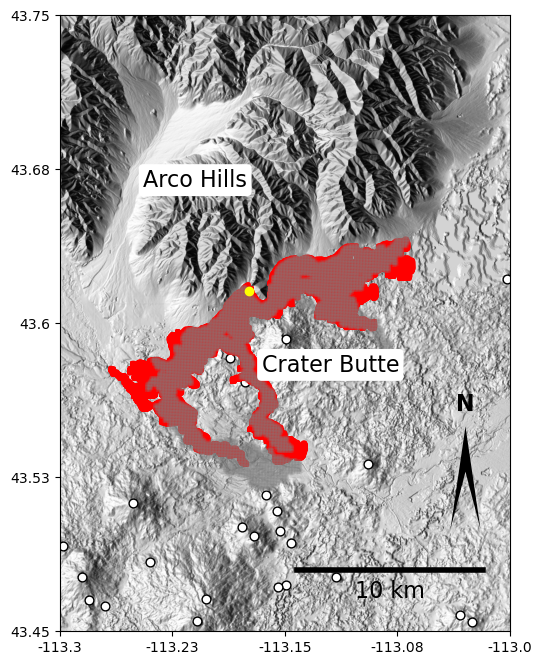

In [23]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt
from numpy import gradient
from pyproj import Proj, transform
import pandas as pd

from pyproj import Transformer
import re
from matplotlib import rcParams
from matplotlib.patches import Polygon, Circle

rcParams['pdf.fonttype'] = 42  # Use TrueType fonts in PDF (Type 42 embeds TTF)

# Function to calculate hillshade
def hillshade(elevation, azimuth=270, angle_altitude=45):
    # Calculate the gradient (slope) of the DEM
    x_grad, y_grad = gradient(elevation, axis=(1, 0))

    # Calculate slope and aspect
    slope = np.arctan(np.sqrt(x_grad**2 + y_grad**2))
    aspect = np.arctan2(-x_grad, y_grad)

    # Convert azimuth and angle to radians
    azimuth_rad = np.deg2rad(azimuth)
    angle_altitude_rad = np.deg2rad(angle_altitude)

    # Calculate the illumination intensity (hillshade)
    zenith = np.pi / 2 - angle_altitude_rad  # Convert altitude to zenith angle
    cos_z = np.cos(zenith) * np.cos(slope) + np.sin(zenith) * np.sin(slope) * np.cos(azimuth_rad - aspect)

    # Normalize the hillshade to 0-255
    hillshade = 255 * (cos_z + 1) / 2
    return hillshade

# File path to the DEM
file_path ="CFPP_DEM30.tif"

points_file_path = "ESRP_vents.ll"  # CSV file with Longitude and Latitude

# Read the point data from the CSV file
points_df = pd.read_csv(points_file_path,  delim_whitespace=True, header=None, names=["Longitude", "Latitude"])
# Open the DEM data using rasterio
with rasterio.open(file_path) as dataset:
    dem_data = dataset.read(1)  # Read the first band (DEM data)
    print(f"DEM data shape: {dem_data.shape}")

    # Get the CRS (Coordinate Reference System) of the DEM
    crs = dataset.crs
    print(f"DEM CRS: {crs}")

    # Get the bounds of the DEM (min and max coordinates in the projected CRS)
    bounds = dataset.bounds
    minx, miny, maxx, maxy = bounds
    print(f"DEM Bounds (Projected): {bounds}")

    # Create a projection object for the DEM's CRS
    proj_dem = Proj(crs)

    # Create arrays for UTM X and Y values based on the number of pixels
    x_values = np.linspace(minx, maxx, dem_data.shape[1])
    y_values = np.linspace(miny, maxy, dem_data.shape[0])

    # Convert the longitude and latitude values from the points data to UTM
    lon_values = points_df['Longitude'].values
    lat_values = points_df['Latitude'].values
    

# Define transformer for UTM Zone 12N to WGS84 lat/lon
transformer = Transformer.from_crs("EPSG:32612", "EPSG:4326", always_xy=True)

   # Calculate hillshade from DEM data
hillshade_data = hillshade(dem_data)

    # Plot the hillshade relief using matplotlib
plt.figure(figsize=(10, 8))
 #   plt.title("Hillshade Relief of 30m DEM")
 #   plt.xlabel("UTM Easting (meters)")
 #   plt.ylabel("UTM Northing (meters)")
plt.imshow(hillshade_data, cmap="gray", extent=(minx, maxx, miny, maxy))
    # Convert each corner to lat/lon


#second lava flow
# Input file
filename = 'flow_CFPP-0_30_1e5'

# Parse the data
coordinates = []
with open(filename, 'r') as f:
    for line in f:
        if line.strip().startswith('#') or not line.strip():
            continue  # skip comments or empty lines
        parts = re.split(r'\s+', line.strip())
        if len(parts) >= 2:
            try:
                easting = float(parts[0])
                northing = float(parts[1])
                coordinates.append((easting, northing))
            except ValueError:
                continue  # skip lines that don't parse


 
for easting, northing in coordinates:
    # Define corners of the 30x30m square (UTM)
    half  = 40.5
    corners_utm = [
        (easting - half, northing - half),
        (easting - half, northing + half),
        (easting + half, northing + half),
        (easting + half, northing - half),
        (easting - half, northing - half)  # close the square
    ]

    # Convert each corner to lat/lon
    corners_latlon = [transformer.transform(x, y) for x, y in corners_utm]
    lons, lats = zip(*corners_latlon)

    
    plt.plot(lons, lats, "red")


# first lava flow
# Input file
filename = 'flow_CFPP-0_81m_1e5'
#filename = 'flow_81mdem_1e5'

coordinates = []
with open(filename, 'r') as f:
    for line in f:
        if line.strip().startswith('#') or not line.strip():
            continue  # skip comments or empty lines
        parts = re.split(r'\s+', line.strip())
        if len(parts) >= 2:
            try:
                easting = float(parts[0])
                northing = float(parts[1])
                coordinates.append((easting, northing))
            except ValueError:
                continue  # skip lines that don't parse


 
for easting, northing in coordinates:
    # Define corners of the 30x30m square (UTM)
    half  = 40.5
    corners_utm = [
        (easting - half, northing - half),
        (easting - half, northing + half),
        (easting + half, northing + half),
        (easting + half, northing - half),
        (easting - half, northing - half)  # close the square
    ]

    # Convert each corner to lat/lon
    corners_latlon = [transformer.transform(x, y) for x, y in corners_utm]
    lons, lats = zip(*corners_latlon)

    
    plt.plot(lons, lats, "gray", alpha=0.2)

     # Plot the points on the DEM
     # Plot the points on the DEM
plt.scatter(lon_values, lat_values, facecolors='white', edgecolors='black', linewidths=1, s=40)
#plot vent 324557.000	4831547.000
vent_long, vent_lat = transformer.transform( 324557.000,4831547.000)
print(vent_long, vent_lat)
plt.plot([vent_long], [vent_lat], marker = "o", color = "yellow")
    # Customize the ticks to show UTM coordinates
plt.xticks(np.linspace(minx, maxx, 5), labels=np.round(np.linspace(minx, maxx, 5), 2))
plt.yticks(np.linspace(miny, maxy, 5), labels=np.round(np.linspace(miny, maxy, 5), 2))

    # Add colorbar for hillshade intensity
 #   plt.colorbar(label="Hillshade Intensity")
# Use xlim and ylim to limit the visible area to the DEM bounding box
plt.xlim(minx, maxx)
plt.ylim(miny, maxy)


# Set aspect ratio using current axes
lat = 43  # or the average latitude of your map
aspect = 1 / np.cos(np.radians(lat))
plt.gca().set_aspect(aspect)


    # Ensure the aspect ratio is correct and avoid distortion
#plt.gca().set_aspect('auto', adjustable='box')

#scalebar
# Center coordinates
center_lon = -113.08
center_lat = 43.48
scale_length = 0.124  # degrees of longitude

# Calculate bar endpoints
x_start = center_lon - scale_length / 2
x_end = center_lon + scale_length / 2
y = center_lat

# Create scale bar plot

plt.plot([x_start, x_end], [y, y], color='black', linewidth=4)  # Scale bar
plt.text(-113.08, 43.47, '10 km', fontsize = 16, ha='center', va='center')

#north arrow
center_x = -113.03
center_y = 43.5
# Triangle dimensions (in degrees)
height = 0.05
width = 0.02
# Triangle size
height = 0.05
width = 0.02
notch_depth = 0.022  # How far the notch cuts into the tip

# Define triangle with an outward-pointing V-notch (notch cuts into the top)
triangle = np.array([
    [center_x - width / 2, center_y],                  # Bottom left
    [center_x, center_y + height],                     # Tip
    [center_x + width / 2, center_y],                  # Bottom right
    [center_x, center_y + height - notch_depth]       # Notch
])


# Add triangle patch
triangle_patch = Polygon(triangle, closed=True, facecolor='black')
plt.gca().add_patch(triangle_patch)

# Add 'N' label above arrow
plt.text(center_x, center_y + height + 0.005, 'N', ha='center', va='bottom', fontsize=16, fontweight='bold')


#label Arco Hills
plt.text(
    -113.21, 43.67, 'Arco Hills',
    fontsize=16,
    color='black',
    ha='center',
    va='center',
    bbox=dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.2')
)

#label Crater Butte
plt.text(
    -113.12, 43.58, 'Crater Butte',
    fontsize=16,
    color='black',
    ha='center',
    va='center',
    bbox=dict(facecolor='white', edgecolor='none', boxstyle='round,pad=0.2')
)

plt.savefig("./CPFF_DEM_compare.pdf")
plt.show()
